# Занятие 6. Почему численный перенос меняет форму сигнала?

Готовые демонстрации к [теоретическому конспекту](lesson_06_theory.md) и [плану на 90 минут](PLAN.md).

**Запуск:** Python 3, NumPy, Matplotlib, IPython; выполнить ячейки сверху вниз (`Run All`).
Анимации встроены в HTML и не требуют FFmpeg, интернета или интерактивного backend.
В доверенном Jupyter-ноутбуке используйте кнопку ▶ под анимацией. Если сохранённый HTML не отображается, выполните соответствующую ячейку заново.

**Основной маршрут:** 1 → 2 → 3 → 4 → 6; в конце кратко показать 8 и 9.
Разделы 5, 7 и дополнения к 8–9 можно оставить для самостоятельного изучения.

Чёрный пунктир — точное решение; синий — upwind; оранжевый — Лакс–Вендрофф; красный — FTCS.
Ни один расчёт не обрезает отрицательные значения или выбросы.

## 0. Подготовка

На кольце длины 1 храним **узловые значения**, без дублирования правого конца.
Три схемы имеют единый интерфейс `step(u, C)`, где `C` содержит знак скорости.
В `solve_periodic` параметр `cfl` положителен и задаёт целевой модуль числа Куранта.
Последний шаг сокращается; фактический `C` вычисляется заново.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (10, 3.8), 'figure.dpi': 100,
    'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.22,
    'axes.spines.top': False, 'axes.spines.right': False,
    'animation.embed_limit': 40,
})
COLORS = {'upwind': '#1673B1', 'lw': '#E08020', 'ftcs': '#C83E3A'}
LABELS = {'upwind': 'Upwind', 'lw': 'Лакс–Вендрофф', 'ftcs': 'FTCS'}

In [2]:
def periodic_gaussian(x):
    """Гладкая периодизация гауссианы; соседние копии убирают шов на кольце."""
    x = np.asarray(x) % 1.0
    return sum(np.exp(-0.5 * ((x - 0.30 + k) / 0.055)**2)
               for k in (-2, -1, 0, 1, 2))


def rectangle(x):
    x = np.asarray(x) % 1.0
    return ((x >= 0.2) & (x < 0.4)).astype(float)


def packet(x):
    x = np.asarray(x) % 1.0
    return periodic_gaussian(x) * np.cos(2 * np.pi * 12 * (x - 0.3))


def smooth_sine(x):
    return 1 + 0.5 * np.sin(2 * np.pi * x)


def exact(profile, x, t, c=1.0):
    return profile((np.asarray(x) - np.remainder(c * t, 1.0)) % 1.0)


def step_ftcs(u, C):
    return u - 0.5 * C * (np.roll(u, -1) - np.roll(u, 1))


def step_upwind(u, C):
    if C >= 0:
        return u - C * (u - np.roll(u, 1))
    return u - C * (np.roll(u, -1) - u)


def step_lw(u, C):
    left, right = np.roll(u, 1), np.roll(u, -1)
    return u - 0.5*C*(right-left) + 0.5*C*C*(right-2*u+left)


STEPS = {'ftcs': step_ftcs, 'upwind': step_upwind, 'lw': step_lw}


def solve_periodic(profile, method='upwind', N=100, c=1.0,
                   cfl=0.8, t_end=1.0, amplitude_limit=1e4):
    """История всех шагов; остановка перед сильным ростом, без обрезки решения."""
    if N < 3 or cfl <= 0 or t_end < 0:
        raise ValueError('Нужны N >= 3, cfl > 0, t_end >= 0')
    x = np.arange(N) / N
    h = 1.0 / N
    u = np.asarray(profile(x), dtype=float).copy()
    if u.shape != x.shape or not np.all(np.isfinite(u)):
        raise ValueError('Начальный профиль должен быть конечным массивом длины N')
    times, states, courant = [0.0], [u.copy()], []
    t, status = 0.0, 'достигнуто конечное время'
    dt_base = cfl * h / abs(c) if c != 0 else max(t_end, 1.0)
    while t < t_end:
        dt = min(dt_base, t_end - t)
        C = c * dt / h
        with np.errstate(over='ignore', invalid='ignore'):
            candidate = STEPS[method](u, C)
        if not np.all(np.isfinite(candidate)) or np.max(np.abs(candidate)) > amplitude_limit:
            status = f'остановка до переполнения: следующий шаг превышает {amplitude_limit:g}'
            break
        t = t_end if t_end - t <= dt_base else t + dt
        u = candidate
        times.append(t)
        states.append(u.copy())
        courant.append(C)
    return dict(x=x, h=h, t=np.array(times), u=np.array(states), C=np.array(courant),
                c=c, cfl=cfl, method=method, status=status, t_requested=t_end)


def diagnostics(result, profile):
    ref = exact(profile, result['x'][None, :], result['t'][:, None], result['c'])
    u, h = result['u'], result['h']
    return dict(mass=h*u.sum(axis=1), e1=h*np.abs(u-ref).sum(axis=1),
                l2=np.sqrt(h*np.sum(u*u, axis=1)),
                peak=u.max(axis=1), minimum=u.min(axis=1), amplitude=np.abs(u).max(axis=1))


def finish(fig):
    fig.tight_layout()
    plt.show()


def inline_animation(fig, update, frames=41):
    """Небольшая автономная JS-анимация с постоянными масштабами."""
    fig.set_dpi(65)
    selected = np.linspace(0, frames-1, min(frames, 31)).astype(int)
    anim = FuncAnimation(fig, update, frames=selected, interval=130, blit=False)
    html = anim.to_jshtml(default_mode='once')
    plt.close(fig)
    return HTML(html)


def compare_animation(results, profile, ylim=(-0.25, 1.25), frames=41):
    first = results[0]
    if any(not np.allclose(r['t'], first['t']) for r in results):
        raise ValueError('Для сравнения нужны общие моменты времени')
    fig, ax = plt.subplots(figsize=(8, 3.3))
    xx = np.linspace(0, 1, 1000, endpoint=False)
    ref_line, = ax.plot(xx, profile(xx), 'k--', lw=1.5, label='Точное')
    lines = [ax.plot(r['x'], r['u'][0], color=COLORS[r['method']],
                     label=LABELS[r['method']])[0] for r in results]
    ax.set(xlim=(0, 1), ylim=ylim, xlabel='x', ylabel='u')
    ax.axhline(0, color='0.7', lw=0.7); ax.axhline(1, color='0.7', lw=0.7)
    ax.legend(loc='upper right', ncol=3, fontsize=9)
    title = ax.set_title('')
    indices = np.linspace(0, len(first['t'])-1, frames).astype(int)
    fig.subplots_adjust(left=0.09, right=0.97, bottom=0.20, top=0.80)
    def update(frame):
        i = indices[frame]
        t = first['t'][i]
        ref_line.set_ydata(exact(profile, xx, t, first['c']))
        for line, r in zip(lines, results): line.set_ydata(r['u'][i])
        C = first['C'][max(i-1, 0)] if len(first['C']) else 0
        title.set_text(f"t={t:.3f}; C={C:.3f}; N={len(first['x'])}; "
                       + ' / '.join(LABELS[r['method']] for r in results))
        return [ref_line, *lines, title]
    return inline_animation(fig, update, frames)

## 1. Точное решение · 0–12 минут

**Вопрос:** что меняется при переносе, а что сохраняется?

$u(x,t)=u_0((x-ct)\bmod1)$. Покажем гауссов импульс, прямоугольник и знакопеременный волновой пакет, $c=+1$ и $c=-1$, два полных оборота.
Для гауссианы суммируем периодические копии, чтобы не создавать искусственного шва на границе.
В графике характеристик координата развёрнута на прямую; пунктирные вертикали обозначают границы соседних копий кольца.

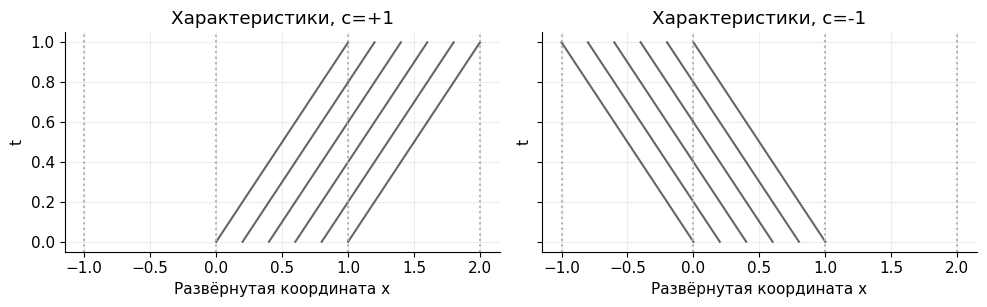

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, c in zip(axes, (1, -1)):
    for xi in np.linspace(0, 1, 6):
        tt = np.linspace(0, 1, 100)
        ax.plot(xi + c*tt, tt, 'k-', alpha=0.6)
    for boundary in (-1, 0, 1, 2): ax.axvline(boundary, color='0.7', ls=':')
    ax.set(xlabel='Развёрнутая координата x', ylabel='t', title=f'Характеристики, c={c:+d}')
finish(fig)

profiles = [periodic_gaussian, rectangle, packet]
profile_names = ['Гауссов импульс', 'Прямоугольник', 'Волновой пакет']
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True)
xx = np.linspace(0, 1, 600, endpoint=False)
exact_lines = []
for row, c in enumerate((1, -1)):
    for col, (profile, name) in enumerate(zip(profiles, profile_names)):
        ax = axes[row, col]
        line, = ax.plot(xx, profile(xx), 'k--')
        exact_lines.append((line, profile, c))
        ax.set(xlim=(0, 1), ylim=(-1.1, 1.15), xlabel='x', ylabel='u', title=f'{name}; c={c:+d}')
clock_title = fig.suptitle('')
fig.tight_layout(rect=(0, 0, 1, 0.93))
def update_exact(frame):
    t = 2 * frame / 40
    for line, profile, c in exact_lines: line.set_ydata(exact(profile, xx, t, c))
    clock_title.set_text(f'Точный сдвиг; t={t:.2f}; N показа=600; CFL не применяется')
    return [item[0] for item in exact_lines] + [clock_title]
display(inline_animation(fig, update_exact, 41))

**Наблюдения:** профиль возвращается через один оборот; отрицательная скорость меняет направление, а не форму. У пакета сохраняются и огибающая, и взаимное положение колебаний.

**Вывод:** потеря пика, размытие или появление новых осцилляций в следующих расчётах вызваны численной схемой.

## 2. FTCS: согласованная, но неустойчивая схема · 12–27 минут

**Вопрос:** почему разумная центральная разность даёт растущее решение?

$G=1-iC\sin\theta$, поэтому $|G|^2=1+C^2\sin^2\theta$.
Берём $N=128$, $C=0.5$, гладкий профиль и возмущение $10^{-6}\sin(2\pi\cdot32x)$.
Его сеточная частота $\theta=\pi/2$ быстро растёт; шахматная мода $\theta=\pi$ для такого опыта не подходит.
Сравниваем также расчёт без специально добавленного возмущения.

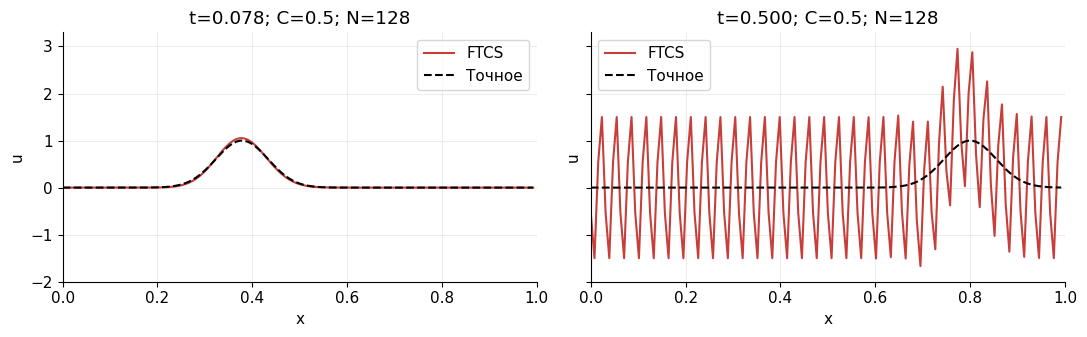

Без добавленного шума: t=1.2000; достигнуто конечное время
Возмущение 10⁻⁶: t=0.7227; остановка до переполнения: следующий шаг превышает 1000


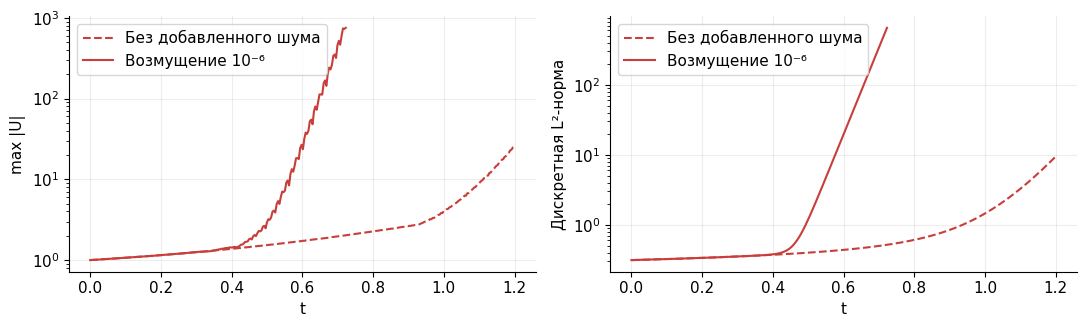

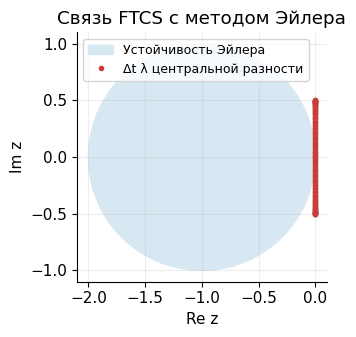

In [4]:
def perturbed(x):
    return periodic_gaussian(x) + 1e-6*np.sin(2*np.pi*32*x)

ftcs_clean = solve_periodic(periodic_gaussian, 'ftcs', N=128, cfl=0.5, t_end=1.2, amplitude_limit=1e3)
ftcs_noisy = solve_periodic(perturbed, 'ftcs', N=128, cfl=0.5, t_end=1.2, amplitude_limit=1e3)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, target in zip(axes, (0.08, 0.5)):
    i = np.argmin(abs(ftcs_noisy['t'] - target))
    t = ftcs_noisy['t'][i]
    ax.plot(ftcs_noisy['x'], ftcs_noisy['u'][i], color=COLORS['ftcs'], label='FTCS')
    ax.plot(ftcs_noisy['x'], exact(perturbed, ftcs_noisy['x'], t), 'k--', label='Точное')
    ax.set(xlim=(0, 1), ylim=(-2, 3.3), xlabel='x', ylabel='u', title=f't={t:.3f}; C=0.5; N=128')
    ax.legend()
finish(fig)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for result, profile, linestyle, label in [
    (ftcs_clean, periodic_gaussian, '--', 'Без добавленного шума'),
    (ftcs_noisy, perturbed, '-', 'Возмущение 10⁻⁶'),
]:
    d = diagnostics(result, profile)
    axes[0].semilogy(result['t'], d['amplitude'], linestyle, color=COLORS['ftcs'], label=label)
    axes[1].semilogy(result['t'], d['l2'], linestyle, color=COLORS['ftcs'], label=label)
    print(f"{label}: t={result['t'][-1]:.4f}; {result['status']}")
for ax, ylabel in zip(axes, ('max |U|', 'Дискретная L²-норма')):
    ax.set(xlabel='t', ylabel=ylabel); ax.legend()
finish(fig)

# Явный Эйлер: его область |1+z| <= 1 не содержит ненулевых мнимых z.
fig, ax = plt.subplots(figsize=(6, 3.5))
phi = np.linspace(0, 2*np.pi, 300)
ax.fill(-1+np.cos(phi), np.sin(phi), color='#D8E8F3', label='Устойчивость Эйлера')
theta = np.linspace(-np.pi, np.pi, 100)
z = -1j*0.5*np.sin(theta)
ax.plot(z.real, z.imag, '.', color=COLORS['ftcs'], label='Δt λ центральной разности')
ax.set(xlabel='Re z', ylabel='Im z', title='Связь FTCS с методом Эйлера', aspect='equal')
ax.legend(loc='upper left', fontsize=9)
finish(fig)

**Наблюдения:** ранний профиль ещё выглядит приемлемо, затем быстро растут амплитуда и норма. Добавленное возмущение делает момент появления неустойчивости воспроизводимым. Даже без него присутствуют ошибки округления и высокочастотные компоненты начального профиля.

**Вывод:** при фиксированном ненулевом CFL сгущение сетки не исправляет FTCS. Уменьшение шага времени может отложить видимый рост, но не помещает ненулевые мнимые собственные значения в область устойчивости Эйлера.

## 3. Upwind: устойчивость и размытие · 27–47 минут

**Вопрос:** какой ценой достигается устойчивость?

Для $c>0$: $U_j^{n+1}=(1-C)U_j^n+CU_{j-1}^n$.
Сравним гауссиану через 1 и 5 оборотов при $C=0.3,0.8,1.0$, на двух сетках.
Ведущий коэффициент численной диффузии $D_{\rm num}=|c|h(1-|C|)/2$.

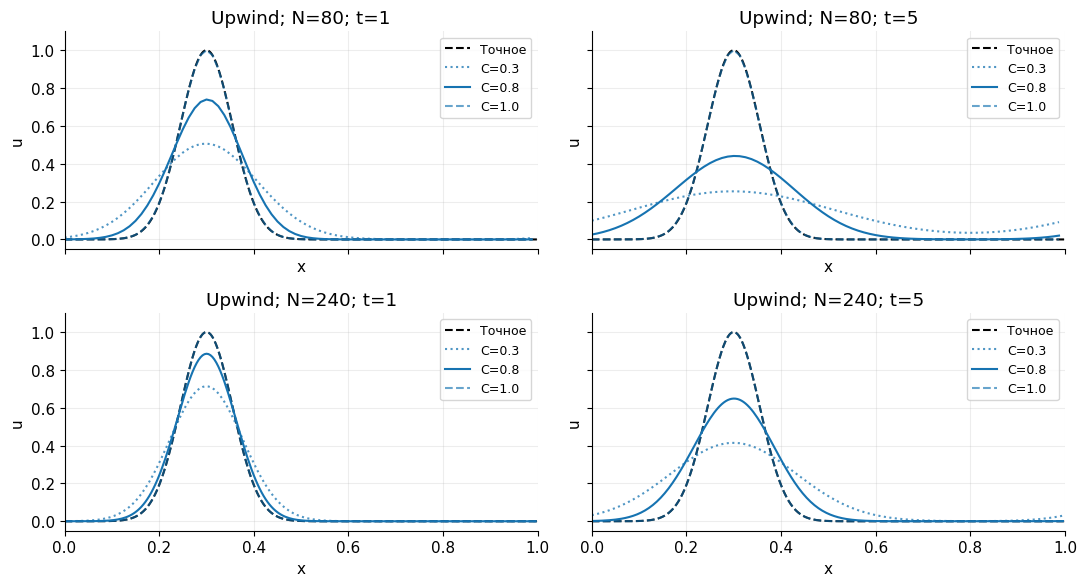

Upwind, c=+1, |C|=1: ошибка возвращения = 6.57e-14
Лакс–Вендрофф, c=+1, |C|=1: ошибка возвращения = 9.86e-14
Upwind, c=-1, |C|=1: ошибка возвращения = 6.57e-14
Лакс–Вендрофф, c=-1, |C|=1: ошибка возвращения = 9.86e-14


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
xx = np.linspace(0, 1, 1000, endpoint=False)
for row, N in enumerate((80, 240)):
    for col, t_end in enumerate((1.0, 5.0)):
        ax = axes[row, col]
        ax.plot(xx, exact(periodic_gaussian, xx, t_end), 'k--', label='Точное')
        for cfl, style, alpha in ((0.3, ':', 0.75), (0.8, '-', 1), (1.0, '--', 0.65)):
            r = solve_periodic(periodic_gaussian, N=N, cfl=cfl, t_end=t_end)
            ax.plot(r['x'], r['u'][-1], style, color=COLORS['upwind'], alpha=alpha, label=f'C={cfl}')
        ax.set(xlim=(0, 1), ylim=(-0.05, 1.1), xlabel='x', ylabel='u', title=f'Upwind; N={N}; t={t_end:g}')
        ax.legend(fontsize=9)
finish(fig)
up_history = solve_periodic(periodic_gaussian, N=100, cfl=0.8, t_end=5)
display(compare_animation([up_history], periodic_gaussian, ylim=(-0.05, 1.15)))

for c in (1, -1):
    for method in ('upwind', 'lw'):
        r = solve_periodic(rectangle, method, N=100, c=c, cfl=1.0, t_end=1)
        print(f'{LABELS[method]}, c={c:+d}, |C|=1: ошибка возвращения = '
              f"{np.max(np.abs(r['u'][-1]-r['u'][0])):.2e}")

**Наблюдения:** upwind не создаёт новых экстремумов в устойчивом диапазоне, но пик снижается и профиль расширяется. Мелкая сетка уменьшает размытие. При фиксированной сетке меньший CFL здесь даёт больше диффузии, а при |C|=1 происходит точный узловой сдвиг.

**Вывод:** уменьшать шаг времени без анализа пространственной ошибки недостаточно. Особый случай |C|=1 не характеризует точность схемы при остальных шагах.

## 4. Лакс–Вендрофф: гладкий профиль и разрыв · 47–65 минут

**Вопрос:** гарантирует ли второй порядок физически допустимый профиль?

$U_j^{n+1}=U_j^n-\frac C2(U_{j+1}^n-U_{j-1}^n)+\frac{C^2}{2}(U_{j+1}^n-2U_j^n+U_{j-1}^n)$.
Берём $N=160$, $C=0.8$. Гауссиану сравним после 5 оборотов, прямоугольник — после одного.

Гауссов импульс; Upwind: min=0.0000, max=0.5710, E1=0.0729
Гауссов импульс; Лакс–Вендрофф: min=-0.0130, max=0.9765, E1=0.01419
Прямоугольник; Upwind: min=0.0000, max=0.9955, E1=0.0563
Прямоугольник; Лакс–Вендрофф: min=-0.1857, max=1.1857, E1=0.03968


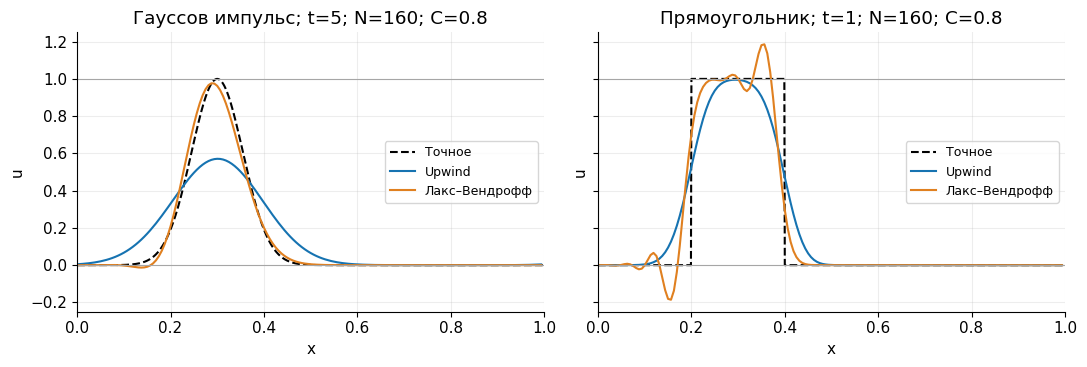

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
comparison_results = {}
for ax, profile, name, t_end in zip(axes, (periodic_gaussian, rectangle),
                                  ('Гауссов импульс', 'Прямоугольник'), (5, 1)):
    ax.plot(xx, exact(profile, xx, t_end), 'k--', label='Точное')
    for method in ('upwind', 'lw'):
        r = solve_periodic(profile, method, N=160, cfl=0.8, t_end=t_end)
        comparison_results[(name, method)] = r
        ax.plot(r['x'], r['u'][-1], color=COLORS[method], label=LABELS[method])
        print(f"{name}; {LABELS[method]}: min={r['u'][-1].min():.4f}, "
              f"max={r['u'][-1].max():.4f}, E1={diagnostics(r, profile)['e1'][-1]:.4g}")
    ax.axhline(0, color='0.65', lw=0.8); ax.axhline(1, color='0.65', lw=0.8)
    ax.set(xlim=(0, 1), ylim=(-0.25, 1.25), xlabel='x', ylabel='u', title=f'{name}; t={t_end}; N=160; C=0.8')
    ax.legend(fontsize=9)
finish(fig)
display(compare_animation([comparison_results[('Прямоугольник', m)] for m in ('upwind', 'lw')], rectangle))

**Наблюдения:** на гауссиане второй порядок лучше сохраняет пик и форму. На прямоугольнике появляются значения ниже 0 и выше 1. Сравните положение максимумов на гладком профиле и величину выбросов на разрыве.

**Вывод:** устойчивость Лакса–Вендроффа не означает монотонности. Высокий порядок на гладком решении не даёт такого же порядка на фронте.

## 5. Диффузия и дисперсия · дополнительная демонстрация

**Вопрос:** почему размытие и осцилляции — разные ошибки?

Сначала увеличим оба фронта прямоугольника при $t=1$, $N=160$, $C=0.8$.
Затем перенесём пакет с несущей частотой 12 на сетке $N=160$ до $t=0.5$.
На спектральных графиках сравним $|G|$ и $c_{\rm phase}/c=-\arg G/(C\theta)$ при $C=0.8$.

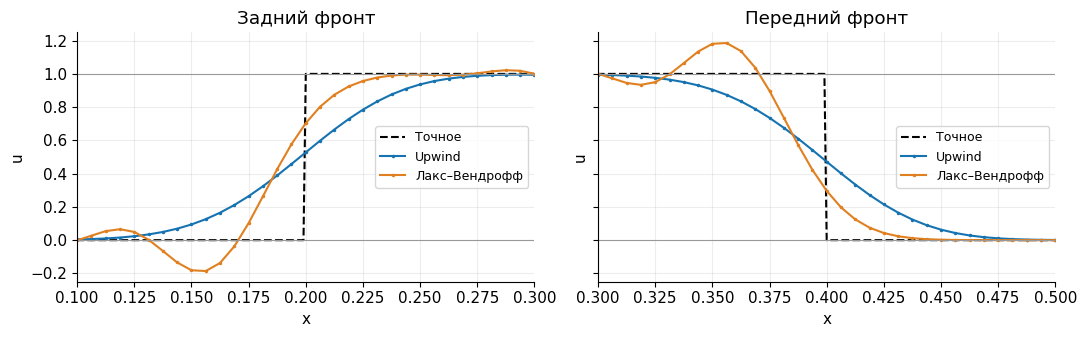

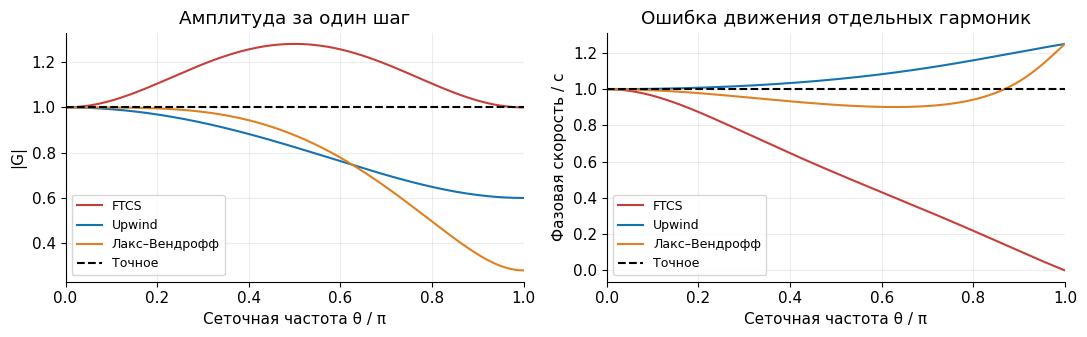

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, window, title in zip(axes, ((0.1, 0.3), (0.3, 0.5)), ('Задний фронт', 'Передний фронт')):
    ax.plot(xx, rectangle(xx), 'k--', label='Точное')
    for method in ('upwind', 'lw'):
        r = comparison_results[('Прямоугольник', method)]
        ax.plot(r['x'], r['u'][-1], '.-', color=COLORS[method], ms=3, label=LABELS[method])
    ax.axhline(0, color='0.6', lw=0.8); ax.axhline(1, color='0.6', lw=0.8)
    ax.set(xlim=window, ylim=(-0.25, 1.25), xlabel='x', ylabel='u', title=title)
    ax.legend(fontsize=9)
finish(fig)
packet_runs = [solve_periodic(packet, m, N=160, cfl=0.8, t_end=0.5) for m in ('upwind', 'lw')]
display(compare_animation(packet_runs, packet, ylim=(-1.15, 1.15)))

C = 0.8
theta = np.linspace(1e-5, np.pi, 600)
factors = {
    'ftcs': 1-1j*C*np.sin(theta),
    'upwind': 1-C+C*np.exp(-1j*theta),
    'lw': 1-1j*C*np.sin(theta)+C*C*(np.cos(theta)-1),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for method, G in factors.items():
    axes[0].plot(theta/np.pi, abs(G), color=COLORS[method], label=LABELS[method])
    axes[1].plot(theta/np.pi, -np.unwrap(np.angle(G))/(C*theta), color=COLORS[method], label=LABELS[method])
for ax in axes:
    ax.axhline(1, color='k', ls='--', label='Точное')
    ax.set(xlabel='Сеточная частота θ / π', xlim=(0, 1)); ax.legend(fontsize=9)
axes[0].set(ylabel='|G|', title='Амплитуда за один шаг')
axes[1].set(ylabel='Фазовая скорость / c', title='Ошибка движения отдельных гармоник')
finish(fig)

**Наблюдения:** upwind сильно подавляет высокие частоты. Лакс–Вендрофф лучше сохраняет их амплитуды, но передаёт фазы с ошибкой; около фронта гармоники складываются в паразитные осцилляции. В пакете меняются относительные положения колебаний и огибающей.

**Вывод:** обе устойчивые схемы обладают и амплитудными, и фазовыми ошибками, но их ведущие механизмы различны. Фазовая скорость отдельной гармоники не равна групповой скорости огибающей.

## 6. Сохранение массы и потеря формы · 65–72 минуты

**Вопрос:** достаточно ли правильной массы для правильного решения?

Гауссов импульс, $N=160$, $C=0.8$, $t\le5$ для устойчивых схем.
FTCS показываем только до $t=0.15$, до сильного роста: после катастрофического разрастания значений точность вычисления суммы теряется.
На отдельных панелях — $M(t)-M(0)$, максимум и $E_1$.

Upwind: max |M-M0|=5.55e-17; E1(t_end)=0.0729; t_end=5
Лакс–Вендрофф: max |M-M0|=8.33e-17; E1(t_end)=0.01419; t_end=5
FTCS: max |M-M0|=2.78e-17; E1(t_end)=0.01878; t_end=0.15


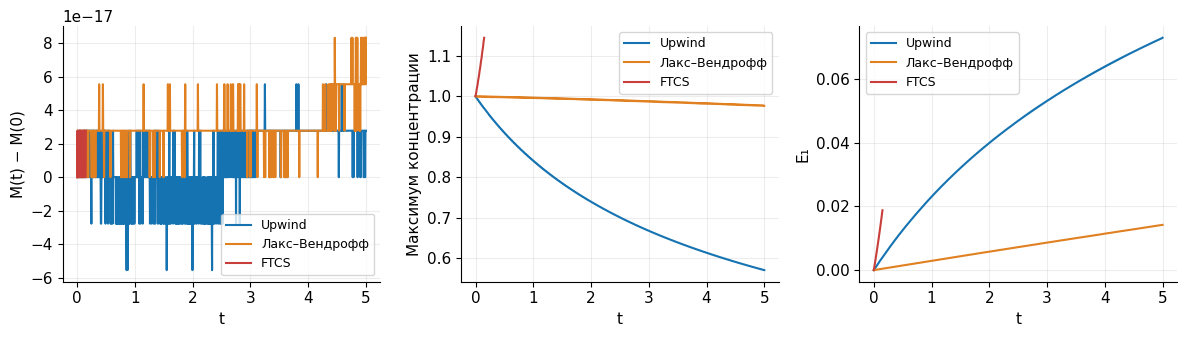

In [8]:
mass_runs = [solve_periodic(periodic_gaussian, m, N=160, cfl=0.8,
                            t_end=0.15 if m == 'ftcs' else 5) for m in ('upwind', 'lw', 'ftcs')]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for r in mass_runs:
    d = diagnostics(r, periodic_gaussian)
    for ax, values in zip(axes, (d['mass']-d['mass'][0], d['peak'], d['e1'])):
        ax.plot(r['t'], values, color=COLORS[r['method']], label=LABELS[r['method']])
    print(f"{LABELS[r['method']]}: max |M-M0|={np.max(abs(d['mass']-d['mass'][0])):.2e}; "
          f"E1(t_end)={d['e1'][-1]:.4g}; t_end={r['t'][-1]:g}")
for ax, ylabel in zip(axes, ('M(t) − M(0)', 'Максимум концентрации', 'E₁')):
    ax.set(xlabel='t', ylabel=ylabel); ax.legend(fontsize=9)
axes[0].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
finish(fig)

**Наблюдения:** масса сохраняется почти до машинной точности, хотя максимум меняется и ошибка профиля растёт. Даже FTCS сохраняет сумму до сильного накопления ошибок округления.

**Вывод:** консервативность, устойчивость и точность — три отдельных свойства. Проверка одного из них не заменяет остальные.

## 7. Сходимость при сгущении сетки · 72–78 минут / самостоятельно

**Вопрос:** виден ли заявленный порядок в вычислительном эксперименте?

$u_0=1+\tfrac12\sin(2\pi x)$, $t=1$, $C=0.8$, $N=25,50,100,200,400$.
Гладкая синусоида выбрана специально: разрыв или слишком узкая неразрешённая гауссиана могут скрыть асимптотический порядок.
$p=\log_2(E_1(h)/E_1(h/2))$. Последний шаг сокращается, если время не кратно базовому шагу.

Upwind


  N= 25: E1=4.759160e-02; p=—
  N= 50: E1=2.454094e-02; p=0.956
  N=100: E1=1.232215e-02; p=0.994
  N=200: E1=6.221657e-03; p=0.986
  N=400: E1=3.126150e-03; p=0.993
Лакс–Вендрофф
  N= 25: E1=7.637262e-03; p=—
  N= 50: E1=1.911911e-03; p=1.998
  N=100: E1=4.736781e-04; p=2.013
  N=200: E1=1.184318e-04; p=2.000
  N=400: E1=2.960861e-05; p=2.000


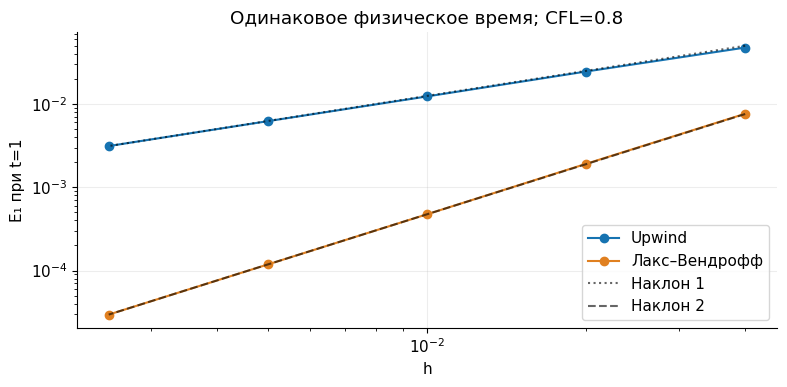

In [9]:
Ns = np.array([25, 50, 100, 200, 400])
convergence = {}
fig, ax = plt.subplots(figsize=(8, 4))
for method in ('upwind', 'lw'):
    errors = np.array([diagnostics(solve_periodic(smooth_sine, method, N=int(N),
                                                cfl=0.8, t_end=1), smooth_sine)['e1'][-1] for N in Ns])
    orders = np.log2(errors[:-1]/errors[1:])
    convergence[method] = (errors, orders)
    ax.loglog(1/Ns, errors, 'o-', color=COLORS[method], label=LABELS[method])
    print(LABELS[method])
    for N, error, order in zip(Ns, errors, np.r_[np.nan, orders]):
        order_text = '—' if np.isnan(order) else f'{order:.3f}'
        print(f'  N={N:3d}: E1={error:.6e}; p={order_text}')
hs = 1/Ns
ax.loglog(hs, convergence['upwind'][0][-1]*(hs/hs[-1]), 'k:', alpha=0.6, label='Наклон 1')
ax.loglog(hs, convergence['lw'][0][-1]*(hs/hs[-1])**2, 'k--', alpha=0.6, label='Наклон 2')
ax.set(xlabel='h', ylabel='E₁ при t=1', title='Одинаковое физическое время; CFL=0.8')
ax.legend()
finish(fig)

**Наблюдения:** на мелких сетках экспериментальные порядки приближаются к 1 и 2. Отличие на грубой сетке не обязательно означает ошибку реализации.

**Вывод:** порядок следует измерять в асимптотическом режиме и на подходящем решении. При C=1 получился бы точный сдвиг, а не содержательный эксперимент на порядок.

## 8. Сигнал проходит через канал · 78–84 минуты

**Вопрос:** что нужно задавать на входе и на выходе?

Канал $[0,1]$, $c=1$, начальная концентрация 0. На входе поток $q(t)=\sin^2(\pi t/0.2)$ при $0\le t\le0.2$ и 0 иначе.
Точный профиль $u(x,t)=q(t-x)$; точный выходной сигнал $q(t-1)$.
Здесь храним **средние по ячейкам** и обновляем их разностью потоков. На выходе нет искусственного условия $u=0$.
Базовый опыт: $N=160$, CFL=0.8, $t\le1.5$.

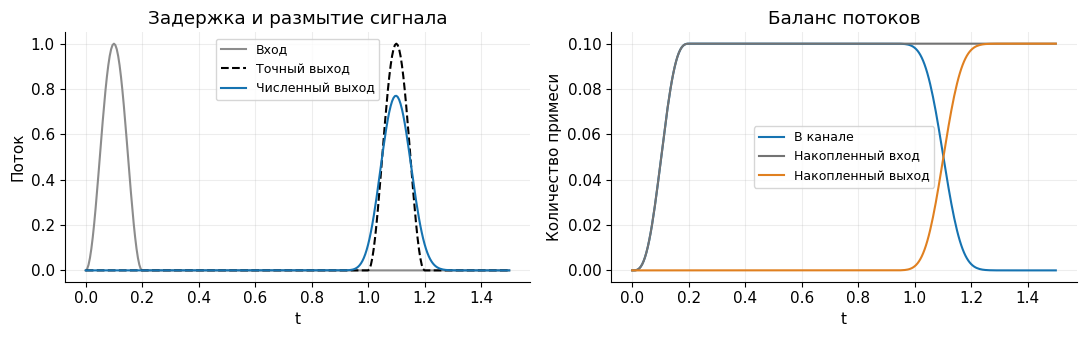

Максимальная невязка дискретного баланса: 4.16e-17


In [10]:
def inlet_pulse(t):
    t = np.asarray(t)
    return np.where((t >= 0) & (t <= 0.2), np.sin(np.pi*t/0.2)**2, 0.0)


def solve_channel(N=160, cfl=0.8, t_end=1.5, speed=None, conservative=True):
    """Положительная стационарная скорость; задан входящий поток q(t)."""
    if speed is None: speed = lambda x: np.ones_like(x)
    faces = np.linspace(0, 1, N+1)
    h = 1/N
    x = (faces[1:]+faces[:-1])/2
    cf = np.asarray(speed(faces), dtype=float)
    cc = np.asarray(speed(x), dtype=float)
    if np.min(cf) <= 0 or np.min(cc) <= 0 or not 0 < cfl <= 1:
        raise ValueError('Нужны положительная скорость и 0 < cfl <= 1')
    dt_base = cfl*h/max(cf.max(), cc.max())
    t, u = 0.0, np.zeros(N)
    ts, us = [t], [u.copy()]
    in_total, out_total = [0.0], [0.0]
    flux_t, flux_in, flux_out = [], [], []
    while t < t_end:
        dt = min(dt_base, t_end-t)
        f = np.r_[float(inlet_pulse(t)), cf[1:]*u]
        if conservative:
            new = u - dt/h*np.diff(f)
        else:
            # Неконсервативная модель: вдоль характеристики сохраняется u.
            upstream = np.r_[float(inlet_pulse(t))/cf[0], u[:-1]]
            new = u - dt/h*cc*(u-upstream)
        flux_t.append(t); flux_in.append(f[0]); flux_out.append(f[-1])
        in_total.append(in_total[-1] + dt*f[0])
        out_total.append(out_total[-1] + dt*f[-1])
        t = t_end if t_end-t <= dt_base else t+dt
        u = new
        ts.append(t); us.append(u.copy())
    return dict(x=x, h=h, t=np.array(ts), u=np.array(us),
                incoming=np.array(in_total), outgoing=np.array(out_total),
                flux_t=np.array(flux_t), flux_in=np.array(flux_in), flux_out=np.array(flux_out),
                cfl=cfl, conservative=conservative)


channel = solve_channel()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(channel['flux_t'], channel['flux_in'], color='0.55', label='Вход')
axes[0].plot(channel['flux_t'], inlet_pulse(channel['flux_t']-1), 'k--', label='Точный выход')
axes[0].plot(channel['flux_t'], channel['flux_out'], color=COLORS['upwind'], label='Численный выход')
axes[0].set(xlabel='t', ylabel='Поток', title='Задержка и размытие сигнала'); axes[0].legend(fontsize=9)
channel_mass = channel['h']*channel['u'].sum(axis=1)
axes[1].plot(channel['t'], channel_mass, label='В канале', color=COLORS['upwind'])
axes[1].plot(channel['t'], channel['incoming'], label='Накопленный вход', color='0.45')
axes[1].plot(channel['t'], channel['outgoing'], label='Накопленный выход', color=COLORS['lw'])
axes[1].set(xlabel='t', ylabel='Количество примеси', title='Баланс потоков'); axes[1].legend(fontsize=9)
finish(fig)
balance_residual = channel_mass-channel_mass[0]-channel['incoming']+channel['outgoing']
print(f'Максимальная невязка дискретного баланса: {np.max(abs(balance_residual)):.2e}')

fig, ax = plt.subplots(figsize=(8, 3.3))
channel_ref, = ax.plot(channel['x'], channel['u'][0], 'k--', label='Точное (центры ячеек)')
channel_line, = ax.plot(channel['x'], channel['u'][0], color=COLORS['upwind'], label='Upwind (средние)')
ax.set(xlim=(0, 1), ylim=(-0.05, 1.15), xlabel='x', ylabel='u')
ax.legend(fontsize=9); channel_title = ax.set_title('')
channel_frames = np.linspace(0, len(channel['t'])-1, 41).astype(int)
fig.subplots_adjust(left=0.09, right=0.97, bottom=0.20, top=0.80)
def update_channel(frame):
    i = channel_frames[frame]; t = channel['t'][i]
    channel_ref.set_ydata(inlet_pulse(t-channel['x']))
    channel_line.set_ydata(channel['u'][i])
    actual_cfl = (channel['t'][i]-channel['t'][i-1])/channel['h'] if i else 0.8
    channel_title.set_text(f'Канал; Upwind; N=160; C={actual_cfl:.3f}; t={t:.3f}')
    return channel_ref, channel_line, channel_title
display(inline_animation(fig, update_channel, 41))

**Наблюдения:** входной сигнал покидает область без отражения, но численный выход ниже и шире точного. Баланс потоков остаётся точным до округления.

**Вывод:** задаём данные там, где информация входит; выходной поток определяется решением. Графическая опорная кривая взята в центрах ячеек; для строгого измерения ошибки конечных объёмов нужно сравнивать со средними точного решения по ячейкам.

### 8а. Переменная скорость · дополнительно

**Вопрос:** одинаковы ли $u_t+c(x)u_x=0$ и $u_t+(c(x)u)_x=0$?

Берём $c(x)=1+0.5\sin(2\pi x)$, $N=240$, CFL=0.8, время наблюдения $t=0.9$.
Время прохождения $s(x)=\int_0^x d\xi/c(\xi)$ вычисляем на густой вспомогательной сетке методом трапеций.
Точный консервативный профиль $q(t-s(x))/c(x)$, неконсервативный — $q(t-s(x))$, так как $c(0)=1$.

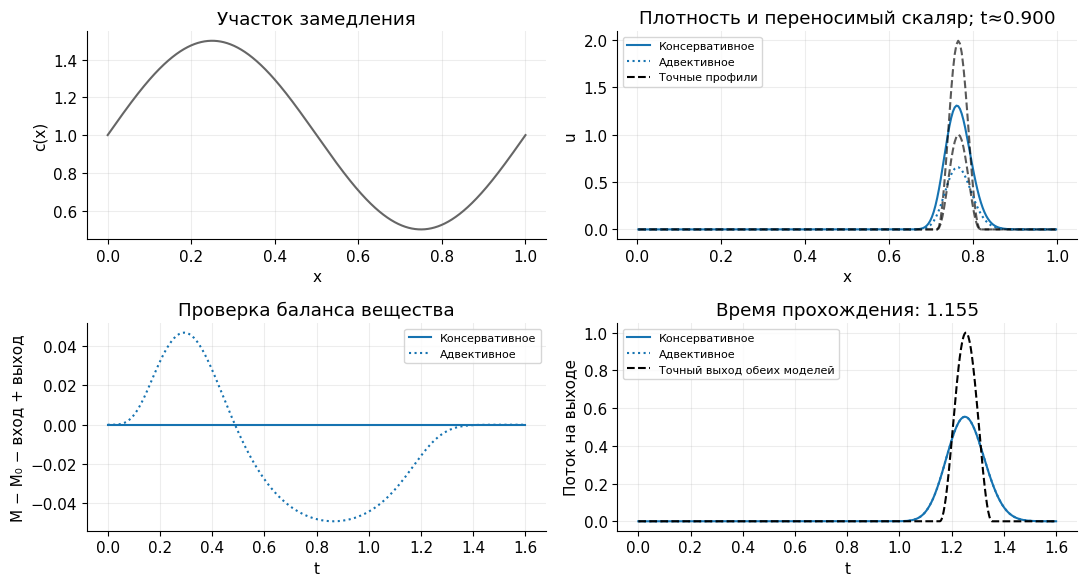

In [11]:
def variable_speed(x): return 1+0.5*np.sin(2*np.pi*x)

variable_cons = solve_channel(N=240, t_end=1.6, speed=variable_speed)
variable_adv = solve_channel(N=240, t_end=1.6, speed=variable_speed, conservative=False)
xfine = np.linspace(0, 1, 20001)
inv_c = 1/variable_speed(xfine)
sfine = np.r_[0, np.cumsum(0.5*(inv_c[:-1]+inv_c[1:])*np.diff(xfine))]
s_centers = np.interp(variable_cons['x'], xfine, sfine)
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
axes[0, 0].plot(xfine, variable_speed(xfine), color='0.4')
axes[0, 0].set(xlabel='x', ylabel='c(x)', title='Участок замедления')
for result, style, name in [(variable_cons, '-', 'Консервативное'), (variable_adv, ':', 'Адвективное')]:
    i = np.argmin(abs(result['t']-0.9)); t = result['t'][i]
    ref = inlet_pulse(t-s_centers)
    if result['conservative']: ref = ref/variable_speed(result['x'])
    axes[0, 1].plot(result['x'], result['u'][i], style, color=COLORS['upwind'], label=name)
    axes[0, 1].plot(result['x'], ref, 'k--', alpha=0.65)
    mass = result['h']*result['u'].sum(axis=1)
    residual = mass-mass[0]-result['incoming']+result['outgoing']
    axes[1, 0].plot(result['t'], residual, style, color=COLORS['upwind'], label=name)
    axes[1, 1].plot(result['flux_t'], result['flux_out'], style, color=COLORS['upwind'], label=name)
axes[0, 1].plot([], [], 'k--', label='Точные профили')
axes[0, 1].set(xlabel='x', ylabel='u', title=f'Плотность и переносимый скаляр; t≈{t:.3f}')
axes[1, 0].set(xlabel='t', ylabel='M − M₀ − вход + выход', title='Проверка баланса вещества')
axes[1, 1].plot(variable_cons['flux_t'], inlet_pulse(variable_cons['flux_t']-sfine[-1]), 'k--', label='Точный выход обеих моделей')
axes[1, 1].set(xlabel='t', ylabel='Поток на выходе', title=f'Время прохождения: {sfine[-1]:.3f}')
for ax in (axes[0, 1], axes[1, 0], axes[1, 1]): ax.legend(fontsize=8)
finish(fig)

**Наблюдения:** в консервативной модели плотность возрастает там, где скорость меньше. В адвективной модели сохраняется значение вдоль характеристики, а баланс количества вещества не выполняется — это другая модель, а не ошибка её решателя.

**Вывод:** форма уравнения имеет физический смысл. Здесь c(0)=c(1)=1, поэтому точные выходные сигналы совпадают при разных внутренних профилях. Проверки только на выходе недостаточно.

## 9. Двумерное вращение · 84–90 минут / самостоятельно

**Вопрос:** сохранит ли численный перенос геометрию пятна?

$\mathbf v=(-2\pi y,2\pi x)$, квадрат $[-1,1]^2$, период вращения 1.
Начальное компактное пятно имеет радиус 0.2 и центр (0.4, 0).
Используем **нерасщеплённое потоковое upwind-обновление** с нулевой концентрацией только на входящих гранях.
Шаг удовлетворяет $\Delta t\max(|v_x|/h+|v_y|/h)\le0.8$.
Начальные средние по ячейкам приближаем значениями в центрах. Точный профиль на картинках также вычисляется в центрах; для исследования порядка нужны точные средние.
Сохраняем выбранные временные срезы, а не каждый шаг двумерного массива.

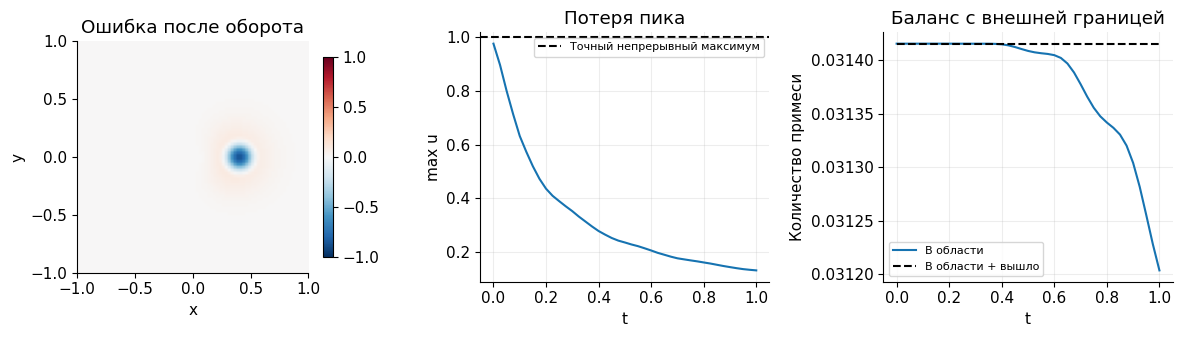

Невязка 2D-баланса: 6.938893903907228e-18


In [12]:
def spot(x, y):
    r2 = ((x-0.4)**2+y*y)/0.2**2
    return np.maximum(0, 1-r2)**3


def slotted_disk(x, y):
    disk = (x-0.4)**2+y*y <= 0.2**2
    slot = (np.abs(x-0.4) < 0.04) & (y < 0.1)
    return (disk & ~slot).astype(float)


def exact_rotation(profile, X, Y, t):
    angle = 2*np.pi*t
    return profile(X*np.cos(angle)+Y*np.sin(angle), -X*np.sin(angle)+Y*np.cos(angle))


def solve_rotation(profile=spot, N=80, cfl=0.8, t_end=1.0, snapshots=41):
    """Конечные объёмы на квадрате; вход 0, выход — из внутренней ячейки."""
    if not 0 < cfl <= 1 or N < 4 or snapshots < 2 or t_end <= 0:
        raise ValueError('Нужны 0<CFL<=1, N>=4, snapshots>=2, t_end>0')
    h = 2/N
    x = -1+(np.arange(N)+0.5)*h
    X, Y = np.meshgrid(x, x)
    u = profile(X, Y).astype(float)
    vx = (-2*np.pi*x)[:, None]  # скорость через вертикальные грани
    vy = (2*np.pi*x)[None, :]   # скорость через горизонтальные грани
    dt_base = cfl/(np.max(abs(vx)/h+abs(vy)/h))
    targets = np.linspace(0, t_end, snapshots)
    history = [u.copy()]
    times, masses, losses = [0.0], [h*h*u.sum()], [0.0]
    t, out_total = 0.0, 0.0
    for target in targets[1:]:
        while t < target:
            dt = min(dt_base, target-t)
            padded_x = np.pad(u, ((0, 0), (1, 1)))
            padded_y = np.pad(u, ((1, 1), (0, 0)))
            fx = np.maximum(vx, 0)*padded_x[:, :-1] + np.minimum(vx, 0)*padded_x[:, 1:]
            fy = np.maximum(vy, 0)*padded_y[:-1, :] + np.minimum(vy, 0)*padded_y[1:, :]
            out_total += dt*h*(np.sum(fx[:, -1]-fx[:, 0])+np.sum(fy[-1, :]-fy[0, :]))
            u = u - dt/h*(np.diff(fx, axis=1)+np.diff(fy, axis=0))
            t = target if target-t <= dt_base else t+dt
        history.append(u.copy()); times.append(t)
        masses.append(h*h*u.sum()); losses.append(out_total)
    return dict(x=x, X=X, Y=Y, h=h, t=np.array(times), u=np.array(history),
                mass=np.array(masses), outflow=np.array(losses), cfl=cfl)


def animate_rotation(result, profile, title):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    ims = []
    for ax, name in zip(axes, ('Точное (в центрах)', 'Upwind (средние ячеек)')):
        im = ax.imshow(result['u'][0], origin='lower', extent=(-1, 1, -1, 1),
                       cmap='viridis', vmin=0, vmax=1, interpolation='nearest')
        ims.append(im)
        ax.set(xlabel='x', ylabel='y', title=name, aspect='equal')
        ax.grid(False)
    fig.subplots_adjust(left=0.07, right=0.84, top=0.79, bottom=0.14, wspace=0.38)
    color_axis = fig.add_axes([0.89, 0.19, 0.02, 0.55])
    fig.colorbar(ims[0], cax=color_axis, label='u')
    heading = fig.suptitle('')
    def update(i):
        t = result['t'][i]
        ims[0].set_data(exact_rotation(profile, result['X'], result['Y'], t))
        ims[1].set_data(result['u'][i])
        heading.set_text(f"{title}; t={t:.3f}; N={len(result['x'])}×{len(result['x'])}; CFL≤{result['cfl']}")
        return *ims, heading
    return inline_animation(fig, update, len(result['t']))


rotation = solve_rotation()
display(animate_rotation(rotation, spot, 'Вращение гладкого пятна'))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
ref_final = exact_rotation(spot, rotation['X'], rotation['Y'], 1)
im = axes[0].imshow(rotation['u'][-1]-ref_final, origin='lower', extent=(-1,1,-1,1),
                    cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].grid(False); axes[0].set(title='Ошибка после оборота', xlabel='x', ylabel='y')
fig.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].plot(rotation['t'], rotation['u'].max(axis=(1,2)), color=COLORS['upwind'])
axes[1].axhline(1, color='k', ls='--', label='Точный непрерывный максимум')
axes[1].set(xlabel='t', ylabel='max u', title='Потеря пика'); axes[1].legend(fontsize=8)
axes[2].plot(rotation['t'], rotation['mass'], label='В области', color=COLORS['upwind'])
axes[2].plot(rotation['t'], rotation['mass']+rotation['outflow'], 'k--', label='В области + вышло')
axes[2].set(xlabel='t', ylabel='Количество примеси', title='Баланс с внешней границей'); axes[2].legend(fontsize=8)
finish(fig)
print('Невязка 2D-баланса:', np.max(abs(rotation['mass']+rotation['outflow']-rotation['mass'][0])))

**Наблюдения:** центр пятна движется по окружности, но численное пятно становится ниже и шире. Одинаковая цветовая шкала не позволяет скрыть потерю пика. Сумма оставшегося и вышедшего вещества сохраняется.

**Вывод:** в нескольких измерениях важны и направление переноса, и суммарное ограничение шага по обеим координатам. Точное пятно не касается границы, но численное размытие может привести к утечке.

### 9а. Диск со щелью · дополнительно

**Вопрос:** какие детали теряются первыми?

Радиус диска 0.2, центр (0.4, 0), щель $|x-0.4|<0.04$, $y<0.1$.
На сетке $80\times80$ ширина щели — лишь несколько ячеек. Покажем пять оборотов при CFL≤0.8.
Это опыт на сохранность геометрии, а не измерение гладкого порядка точности.

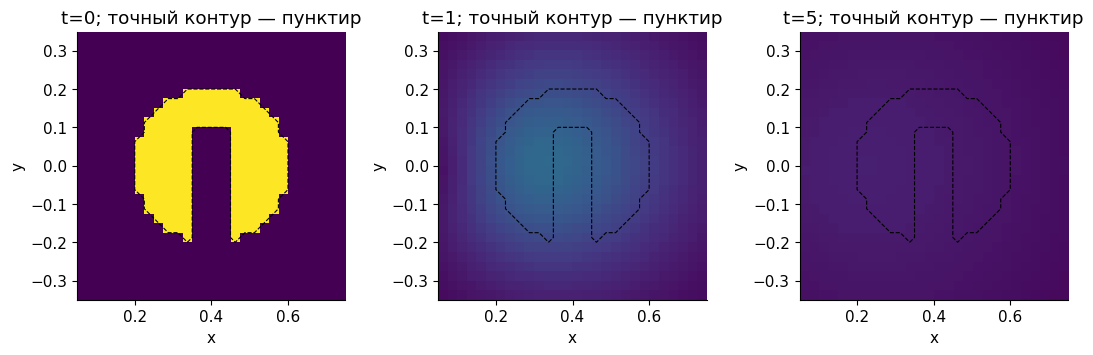

In [13]:
slot_rotation = solve_rotation(slotted_disk, N=80, t_end=5, snapshots=51)
display(animate_rotation(slot_rotation, slotted_disk, 'Диск со щелью: пять оборотов'))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, target in zip(axes, (0, 1, 5)):
    i = np.argmin(abs(slot_rotation['t']-target))
    ax.imshow(slot_rotation['u'][i], origin='lower', extent=(-1,1,-1,1),
              vmin=0, vmax=1, cmap='viridis', interpolation='nearest')
    ax.contour(slot_rotation['X'], slot_rotation['Y'],
               exact_rotation(slotted_disk, slot_rotation['X'], slot_rotation['Y'], target),
               levels=[0.5], colors='black', linestyles='--', linewidths=0.8)
    ax.set(xlim=(0.05, 0.75), ylim=(-0.35, 0.35), xlabel='x', ylabel='y',
           title=f't={target}; точный контур — пунктир', aspect='equal')
    ax.grid(False)
finish(fig)

**Наблюдения:** щель заполняется численно, граница диска расплывается, а после нескольких оборотов начальная геометрия почти не различима.

**Вывод:** сохранение массы не означает сохранения тонких деталей. Для дальнейшего исследования нужны сгущение сетки и схемы высокого разрешения.

## После занятия

Выбрать один сюжет из [домашнего задания](../README.md#занятие-6-уравнение-переноса): кольцо, канал или двумерное вращение.
Обязательные проверки в каждом сюжете — точный эталон, изменение шага и осмысленная диагностика ошибок.

**Вопрос для обсуждения:** почему точный сдвиг функции прост, а его численное воспроизведение требует анализа устойчивости, диссипации, дисперсии и балансов?